## Dataset Source, Licence & EDA Notes

- **Dataset:** Malicious URLs Dataset (ISCX-URL2016)
- **Source URL:** `https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset`
- **Licence & Usage Terms:** CC0: Public Domain. Available under public domain dedication; cited properly in project documentation and used strictly for academic coursework.
- **Data Safety & Ethics:** Static public dataset used exclusively for offline machine learning experiments and academic evaluation. No live network traffic capture, active scanning, or unauthorized probing is performed on any network.

### EDA & Class Imbalance Observations
- Raw rows inspected, missing values checked, exact duplicate rows removed, and remaining records saved for feature engineering.
- The `type` column shows class imbalance across URL categories (`benign`, `phishing`, `defacement`, `malware`).
- **Imbalance Handling Plan:** Documented in EDA; handled inside the modeling/training stage after train/test splitting (e.g., class weighting and F1/Recall-focused evaluation) to prevent data leakage.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the ISCX-URL2016 dataset
# Update DATASET_PATH to match your uploaded file name or Google Drive path
DATASET_PATH = "malicious_phish.csv"

if os.path.exists(DATASET_PATH):
    df = pd.read_csv(DATASET_PATH)
    print(f"[INFO] Loaded dataset successfully. Shape: {df.shape}")
else:
    raise FileNotFoundError(
        f"[ERROR] File not found at '{DATASET_PATH}'. Check the path or upload the file."
    )

[INFO] Loaded dataset successfully. Shape: (651191, 2)


In [3]:
print("\n--- Columns ---")
print(df.columns.tolist())

print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- Dataset Info ---")
print(df.info())


--- Columns ---
['url', 'type']

--- First 5 Rows ---
                                                 url        type
0                                   br-icloud.com.br    phishing
1                mp3raid.com/music/krizz_kaliko.html      benign
2                    bopsecrets.org/rexroth/cr/1.htm      benign
3  http://www.garage-pirenne.be/index.php?option=...  defacement
4  http://adventure-nicaragua.net/index.php?optio...  defacement

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 651191 entries, 0 to 651190
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     651191 non-null  object
 1   type    651191 non-null  object
dtypes: object(2)
memory usage: 9.9+ MB
None


In [4]:
missing_count = df.isnull().sum()
print("\n--- Missing Values per Column ---")
print(missing_count[missing_count > 0] if missing_count.sum() > 0 else "No missing values.")


--- Missing Values per Column ---
No missing values.


In [6]:
df = df.dropna().reset_index(drop=True)

there are non missing value, so this line doesn't important. I kept it if a new data contain a missing value.

In [7]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)
print(f"\n[INFO] Removed {rows_before - rows_after} duplicate rows. Remaining rows: {rows_after}")


[INFO] Removed 10066 duplicate rows. Remaining rows: 641125



--- Class Distribution for 'type' ---
             count  percentage_%
type                            
benign      428080         66.77
defacement   95308         14.87
phishing     94092         14.68
malware      23645          3.69


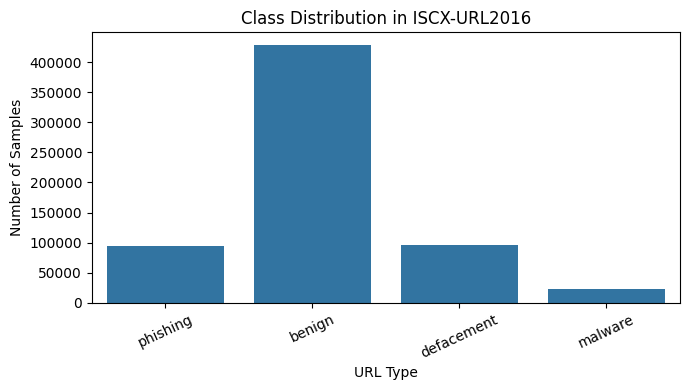

In [8]:
TARGET_COL = "type"

if TARGET_COL in df.columns:
    print(f"\n--- Class Distribution for '{TARGET_COL}' ---")
    counts = df[TARGET_COL].value_counts()
    percentages = df[TARGET_COL].value_counts(normalize=True) * 100
    summary_df = pd.DataFrame({"count": counts, "percentage_%": percentages.round(2)})
    print(summary_df)

    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=TARGET_COL)
    plt.title("Class Distribution in ISCX-URL2016")
    plt.xlabel("URL Type")
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()
else:
    print(f"[WARNING] Column '{TARGET_COL}' was not found. Available columns: {df.columns.tolist()}")

In [11]:
# Check if any URL has conflicting labels ('type')
conflicting_urls = df.groupby("url")["type"].nunique()
conflicting_urls = conflicting_urls[conflicting_urls > 1]

print(f"[INFO] URLs with conflicting 'type' labels: {len(conflicting_urls)}")

if len(conflicting_urls) > 0:
    print("\n--- Sample Conflicting URLs ---")
    sample_conf = conflicting_urls.index[:5]
    print(df[df["url"].isin(sample_conf)].sort_values("url"))

[INFO] URLs with conflicting 'type' labels: 6

--- Sample Conflicting URLs ---
                                                url      type
323002                  ebookstore.sony.com/reader/    benign
606876                  ebookstore.sony.com/reader/  phishing
255448     en.wikipedia.org/wiki/Desktop_publishing    benign
606766     en.wikipedia.org/wiki/Desktop_publishing  phishing
209852                 en.wikipedia.org/wiki/E-book    benign
606800                 en.wikipedia.org/wiki/E-book  phishing
271287        groups.yahoo.com/group/Band-in-a-Box/    benign
615907        groups.yahoo.com/group/Band-in-a-Box/  phishing
178637  memory.loc.gov/ammem/ccmphtml/colahome.html    benign
599823  memory.loc.gov/ammem/ccmphtml/colahome.html  phishing


In [9]:
OUTPUT_PATH = "Cleaned_ISCX_URL2016.csv"
df.to_csv(OUTPUT_PATH, index=False)
print(f"\n[SUCCESS] Cleaned dataset saved to '{OUTPUT_PATH}'.")


[SUCCESS] Cleaned dataset saved to 'Cleaned_ISCX_URL2016.csv'.
